# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

**Student SRN:** pes2ug24cs513

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Markdown cells marked **Reflection** are answered below.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**Completed:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:

frame_bytes = 1920 * 1080 * 3 * 1  # 8 bits = 1 byte per channel
frame_mb = frame_bytes / 1_000_000


frames_per_day = 30 * 24 * 60 * 60


fleet_bytes = frame_bytes * frames_per_day * 400
fleet_tb = fleet_bytes / (1024 ** 4)


small_frame_bytes = 640 * 360 * 3
small_frames_per_day = 10 * 24 * 60 * 60
fleet_tb_small = small_frame_bytes * small_frames_per_day * 400 / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage, but it can erase evidence. Spatially, a small object such as a key, tool, or identifying feature may become too few pixels to distinguish. Temporally, an event that happens between 10 fps samples (such as a brief handoff or the exact start of an impact) may never appear in a recorded frame.

_Your answer:_

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**Completed:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

Contrast before: 0.609  ->  after: 1.000


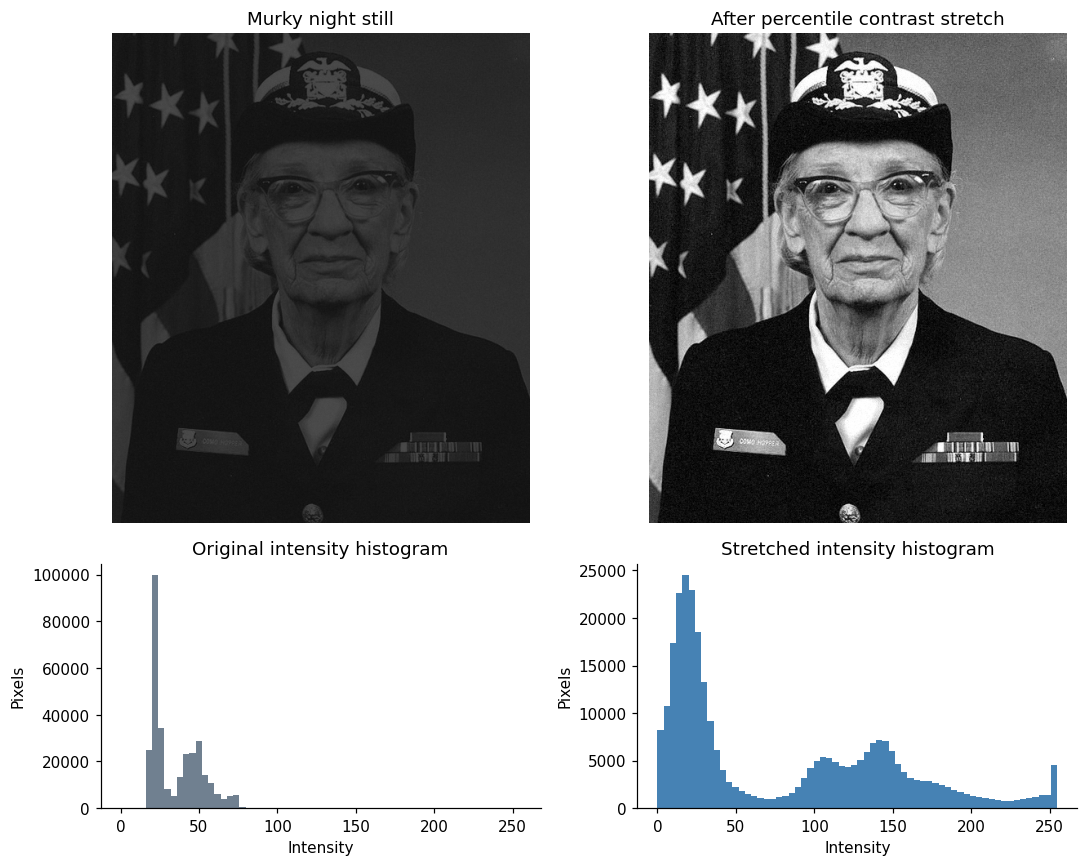

In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# Robust Michelson contrast, using the 1st and 99th percentile limits
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# Map the occupied robust range to the full display range, clipping outliers
stretched = np.clip((night_still - p1) * 255 / (p99 - p1), 0, 255)
c_after = michelson(np.percentile(stretched, 99), np.percentile(stretched, 1))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Murky night still")
axes[0, 0].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="slategray")
axes[1, 0].set(title="Original intensity histogram", xlabel="Intensity", ylabel="Pixels")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("After percentile contrast stretch")
axes[0, 1].axis("off")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="steelblue")
axes[1, 1].set(title="Stretched intensity histogram", xlabel="Intensity", ylabel="Pixels")
plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** The original histogram is narrow and concentrated at the dark end, which is the lecture's low-contrast distribution. Stretching spreads those existing intensity values across the display range, making differences easier to see; it changes their display mapping but creates no new scene detail. A histogram keeps only counts of intensity values and discards their locations, so different pictures can have the same histogram.

_Your answer:_

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**Completed:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing intervals (s): [(np.float64(68.7), np.float64(68.7)), (np.float64(68.8), np.float64(68.8)), (np.float64(68.9), np.float64(70.5)), (np.float64(70.6), np.float64(70.8)), (np.float64(70.9), np.float64(71.1)), (np.float64(71.2), np.float64(71.6)), (np.float64(71.7), np.float64(72.0)), (np.float64(72.1), np.float64(72.1)), (np.float64(72.2), np.float64(72.7)), (np.float64(72.8), np.float64(73.2)), (np.float64(73.3), np.float64(73.7)), (np.float64(73.8), np.float64(73.9)), (np.float64(74.0), np.float64(74.0)), (np.float64(74.1), np.float64(74.2)), (np.float64(74.3), np.float64(74.7)), (np.float64(74.7), np.float64(75.4)), (np.float64(75.4), np.float64(75.5)), (np.float64(75.5), np.float64(75.6)), (np.float64(75.6), np.float64(75.7)), (np.float64(75.7), np.float64(75.7)), (np.float64(75.8), np.float64(75.9)), (np.float64(76.0), np.float64(76.5)), (np.float64(76.6), np.float64(76.9)), (np.float64(77.0), np.float64(78.1))]
Running intervals (s): [(np.float64(78.6), np.float64(86.0))]
F

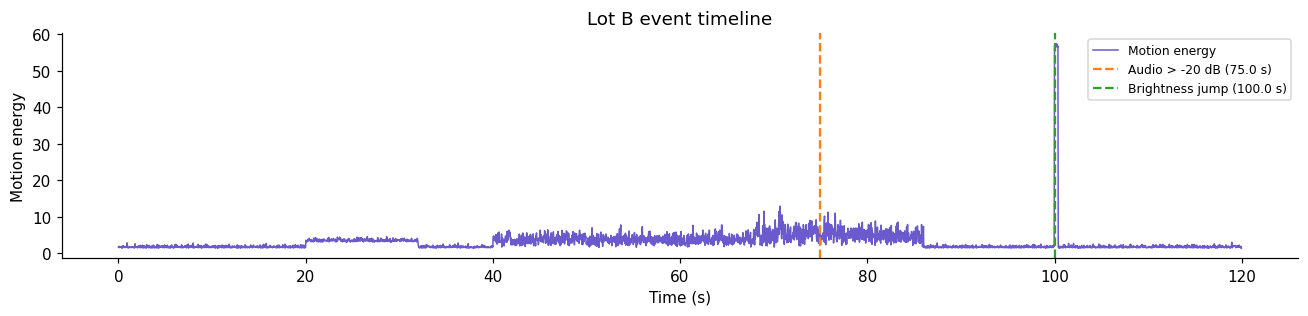

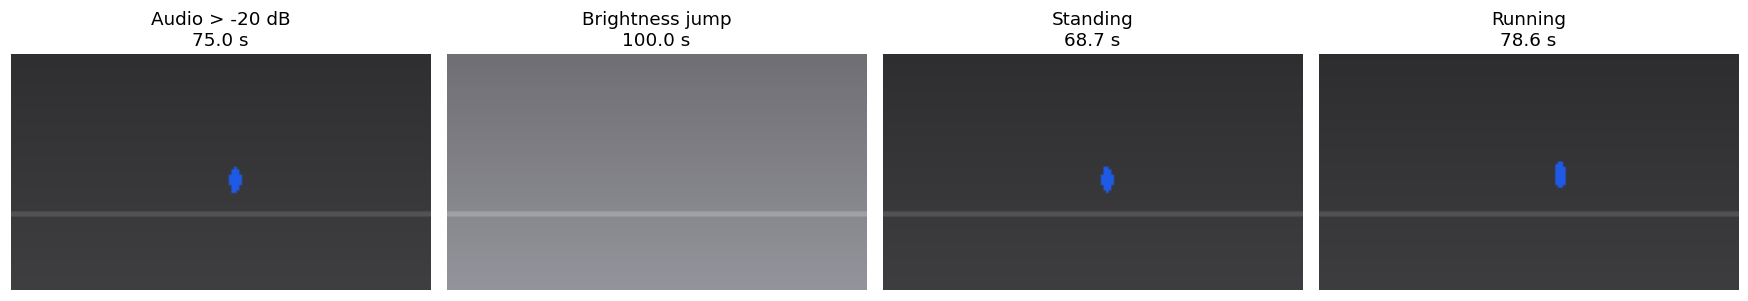

In [4]:

px = cctv["person_x"].astype(float)
py = cctv["person_y"].astype(float)
dt = cctv["time_s"].diff(FPS)
dx = px.diff(FPS)
dy = py.diff(FPS)
speed = np.sqrt(dx**2 + dy**2) / dt
valid_person = px.notna() & py.notna() & px.shift(FPS).notna() & py.shift(FPS).notna()
speed = speed.where(valid_person)


def print_ranges(mask, label):
    mask = mask.fillna(False).to_numpy()
    starts = np.flatnonzero(mask & ~np.r_[False, mask[:-1]])
    ends = np.flatnonzero(mask & ~np.r_[mask[1:], False])
    times = cctv["time_s"].to_numpy()
    ranges = [(times[a], times[b]) for a, b in zip(starts, ends)]
    print(f"{label} intervals (s): {[(round(a, 1), round(b, 1)) for a, b in ranges]}")
    return ranges
standing_ranges = print_ranges(valid_person & (speed < 3), "Standing")
running_ranges = print_ranges(valid_person & (speed > 25), "Running")


above_audio = cctv["audio_level_db"] > -20
audio_event_idx = int(np.flatnonzero(above_audio.to_numpy())[0]) if above_audio.any() else None
brightness_jump = cctv["mean_brightness"].diff() > 40
lighting_event_idx = int(np.flatnonzero(brightness_jump.to_numpy())[0]) if brightness_jump.any() else None
print("First audio > -20 dB:", None if audio_event_idx is None else (audio_event_idx, cctv.loc[audio_event_idx, "time_s"]))
print("Brightness jump > 40:", None if lighting_event_idx is None else (lighting_event_idx, cctv.loc[lighting_event_idx, "time_s"]))


fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv["time_s"], cctv["motion_energy"], color="slateblue", lw=1, label="Motion energy")
event_indices = [(audio_event_idx, "Audio > -20 dB", "tab:orange"), (lighting_event_idx, "Brightness jump", "tab:green")]
for idx, label, color in event_indices:
    if idx is not None:
        t = cctv.loc[idx, "time_s"]
        ax.axvline(t, color=color, ls="--", label=f"{label} ({t:.1f} s)")
ax.set(xlabel="Time (s)", ylabel="Motion energy", title="Lot B event timeline")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()


keyframes = []
for idx, label, _ in event_indices:
    if idx is not None: keyframes.append((idx, label))
for ranges, label in [(standing_ranges, "Standing"), (running_ranges, "Running")]:
    if ranges:
        t = ranges[0][0]
        idx = int((cctv["time_s"] - t).abs().argmin())
        keyframes.append((idx, label))
fig, axes = plt.subplots(1, len(keyframes), figsize=(4 * len(keyframes), 3))
if len(keyframes) == 1: axes = [axes]
for ax, (idx, label) in zip(axes, keyframes):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{label}\n{cctv.loc[idx, 'time_s']:.1f} s")
    ax.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** Uniform keyframes every 20 seconds would most likely miss the short audio event at 75 s and the sudden lighting change at 100 s, because neither time is a 20-second sample. Content-based keyframes select frames around detected changes and events, so the sparse but important moments are represented.

_Your answer:_

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**Completed:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

{'Reference: gunshot': '0.003', 'Reference: glass break': '0.989', 'MYSTERY (74.5-76.5 s)': '0.873'}
Verdict: the sound is most consistent with glass break (nearest reference by >3 kHz energy fraction).


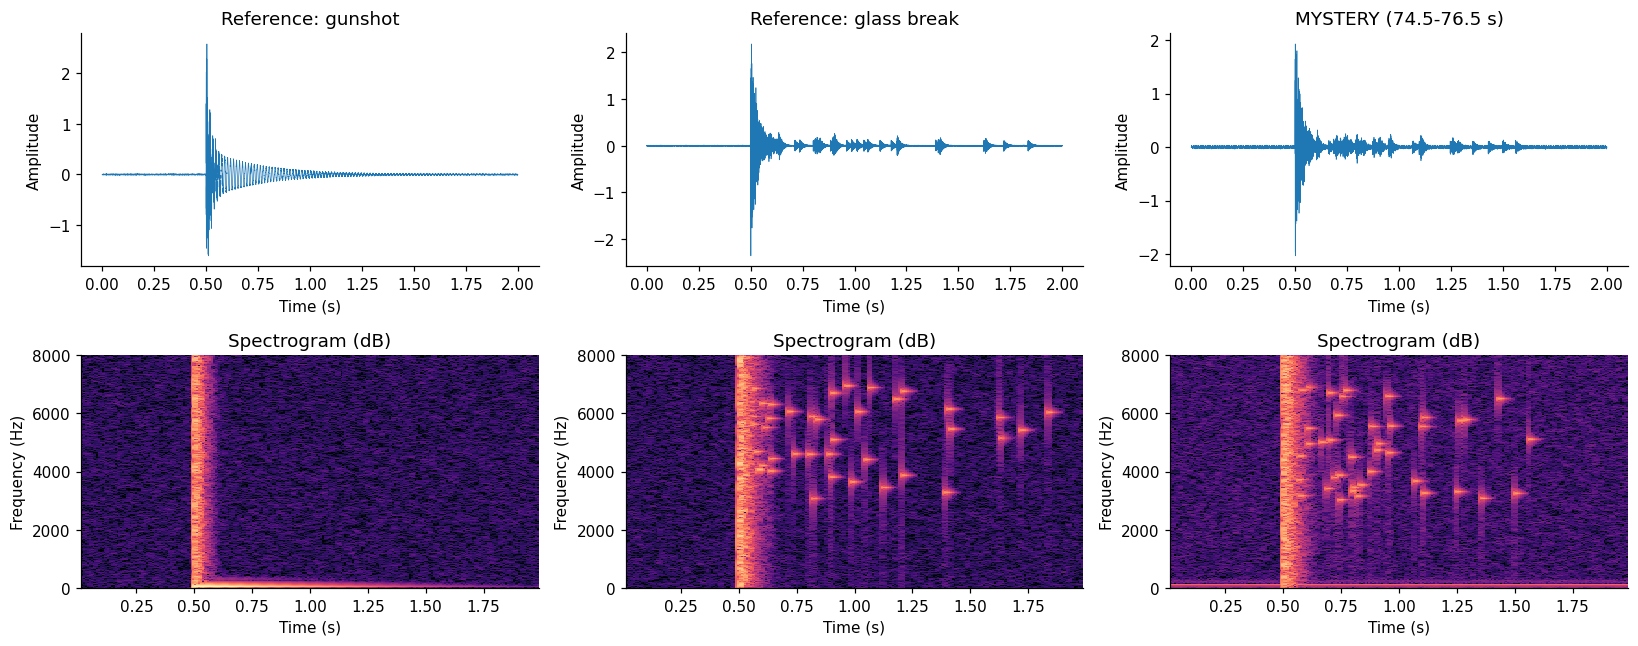

In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, (name, x) in enumerate(clips.items()):
    times = np.arange(len(x)) / FS
    axes[0, col].plot(times, x, lw=0.45)
    axes[0, col].set(title=name, xlabel="Time (s)", ylabel="Amplitude")
    freqs, spec_times, power = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, col].pcolormesh(spec_times, freqs, 10 * np.log10(power + 1e-12), shading="auto", cmap="magma", vmin=-100, vmax=-30)
    axes[1, col].set(xlabel="Time (s)", ylabel="Frequency (Hz)", ylim=(0, 8000))
    axes[1, col].set_title("Spectrogram (dB)")
plt.tight_layout(); plt.show()

# Fraction of spectral power above 3 kHz, from 0.2 to 1.2 s after the 0.5 s impact
hf_fraction = {}
for name, x in clips.items():
    freqs, spec_times, power = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    window = (spec_times >= 0.7) & (spec_times <= 1.7)
    total = power[:, window].sum()
    hf_fraction[name] = power[(freqs > 3000), :][:, window].sum() / total if total else np.nan

print({name: f"{value:.3f}" for name, value in hf_fraction.items()})
# Compare the mystery with each reference using the high-frequency energy fraction
ref_distances = {name: abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction[name]) for name in list(clips)[:2]}
verdict = min(ref_distances, key=ref_distances.get)
print(f"Verdict: the sound is most consistent with {verdict.removeprefix('Reference: ')} (nearest reference by >3 kHz energy fraction).")

**Reflection:** The waveforms show the timing and loudness of the impacts, but their sharp transients look similar, so they do not confidently distinguish the two sounds. A spectrogram adds time, frequency, and magnitude (shown by color intensity). The mystery's lingering scattered high-frequency specks after the impact match the glass reference and distinguish it from the gunshot's brief broadband crack followed by low-frequency decay.

_Your answer:_

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**Completed:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

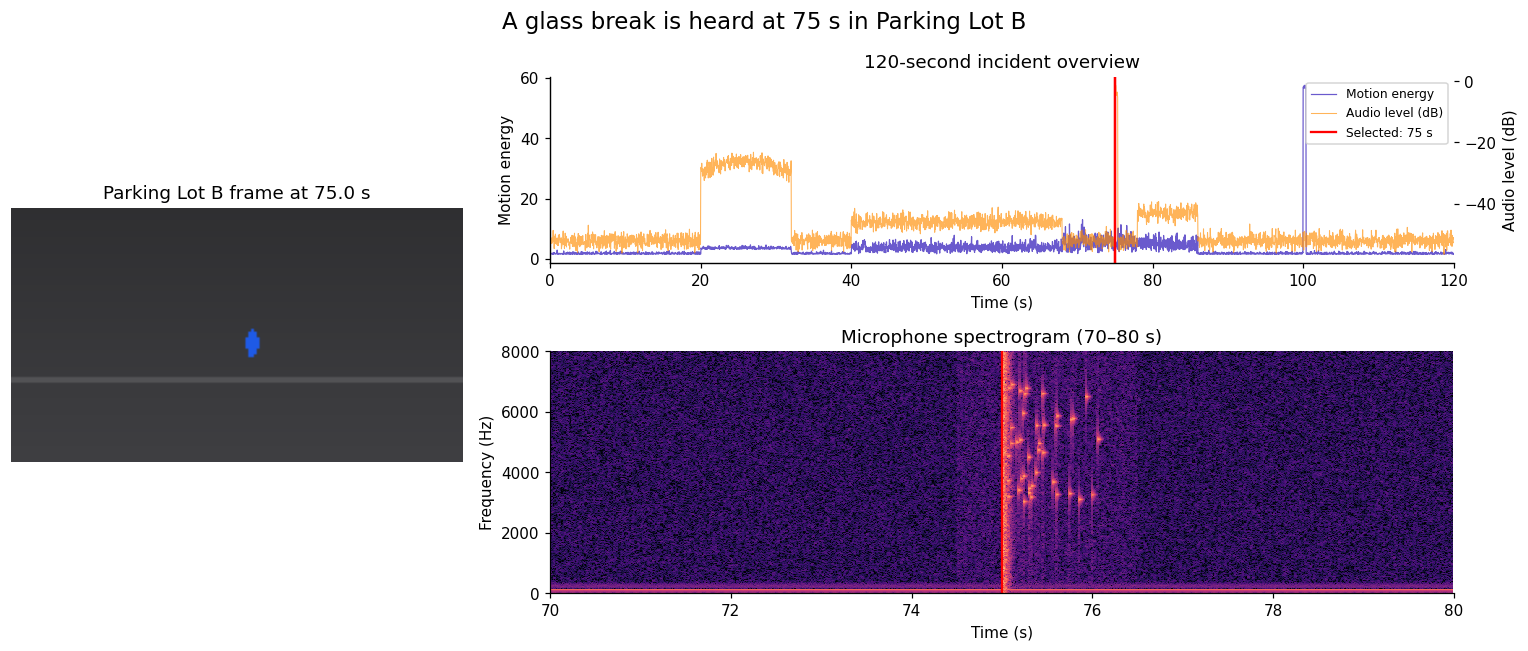

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# Left: video still at the selected incident timestamp
ax_img = fig.add_subplot(gs[:, 0])
idx_sel = int((cctv["time_s"] - t_sel).abs().argmin())
ax_img.imshow(render_frame(cctv.iloc[idx_sel]))
ax_img.set_title(f"Parking Lot B frame at {cctv.loc[idx_sel, 'time_s']:.1f} s")
ax_img.axis("off")

# Top right: synchronized full-duration motion and audio overview
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv["time_s"], cctv["motion_energy"], color="slateblue", lw=0.8, label="Motion energy")
ax_audio = ax_timeline.twinx()
ax_audio.plot(cctv["time_s"], cctv["audio_level_db"], color="darkorange", alpha=0.65, lw=0.7, label="Audio level (dB)")
ax_timeline.axvline(t_sel, color="red", lw=1.5)
ax_audio.axvline(t_sel, color="red", lw=1.5, label="Selected: 75 s")
ax_timeline.set(xlim=(0, 120), xlabel="Time (s)", ylabel="Motion energy", title="120-second incident overview")
ax_audio.set_ylabel("Audio level (dB)")
lines1, labels1 = ax_timeline.get_legend_handles_labels(); lines2, labels2 = ax_audio.get_legend_handles_labels()
ax_timeline.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8)

# Bottom right: 10-second audio spectrogram with the same selected time
ax_spec = fig.add_subplot(gs[1, 1])
freqs, spec_times, power = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_spec.pcolormesh(70 + spec_times, freqs, 10 * np.log10(power + 1e-12), shading="auto", cmap="magma", vmin=-100, vmax=-30)
ax_spec.axvline(t_sel, color="red", lw=1.5)
ax_spec.set(xlim=(70, 80), ylim=(0, 8000), xlabel="Time (s)", ylabel="Frequency (Hz)", title="Microphone spectrogram (70–80 s)")
fig.suptitle("A glass break is heard at 75 s in Parking Lot B", fontsize=15)
plt.tight_layout(); plt.show()

**Reflection:** If the audio were shifted 2 s later than the video, the sound at 75 s would be aligned with the wrong video frame, which could falsely identify who or what caused it. The synchronized spectrogram panel would expose the mismatch: its red marker would no longer line up with the audio's impact, while the timeline's red marker still marks 75 s.

_Your answer:_

**Reflection (final):** At 75.0 s, the Lot B microphone records a brief impact that matches the glass-break reference; at 100.0 s the video also shows a sudden brightness increase that should be checked as a lighting change. I would put the synchronized view first because it links the timeline overview to the detailed audio pattern at the same time, moving from event detection to meaning. The spectrogram's time, frequency, and magnitude view shows the lingering high-frequency tinkle that supports the glass classification. Uncompressed 1080p at 30 fps would require about 5,868 TB per day for 400 cameras, while 640×360 at 10 fps requires about 217 TB per day. Use the lower rate for routine retention, but preserve full-resolution, full-rate footage around flagged events so brief spatial details and fast actions are not lost.

_Your final briefing here:_